Libraries imported successfully!


Saving .csv to .csv

Dataset loaded successfully!
Dataset Shape: (10000, 6)


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB

Statistical Summary:


,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.583300,55.224800
std,2.589309,17.343152,1.695863,2.867348,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000



Missing Values:
Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

Duplicate Rows Before Cleaning:
127

Duplicate Rows After Cleaning:
0

Cleaned Dataset Shape: (9873, 6)

Dataset Columns:
['Hours Studied', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index']


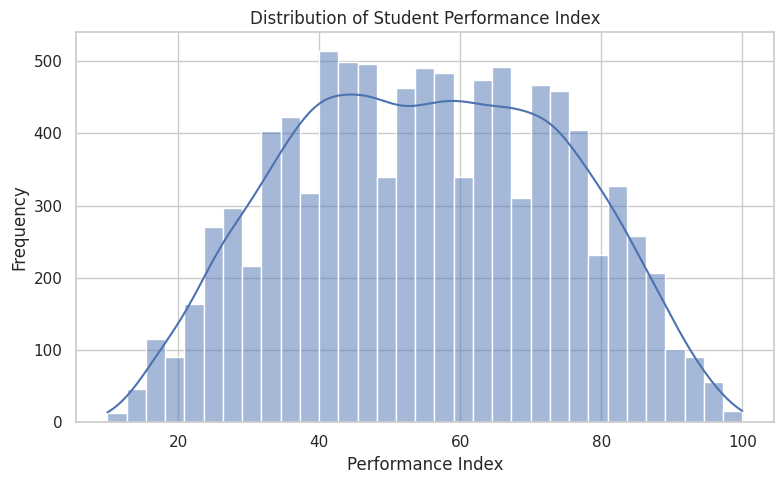

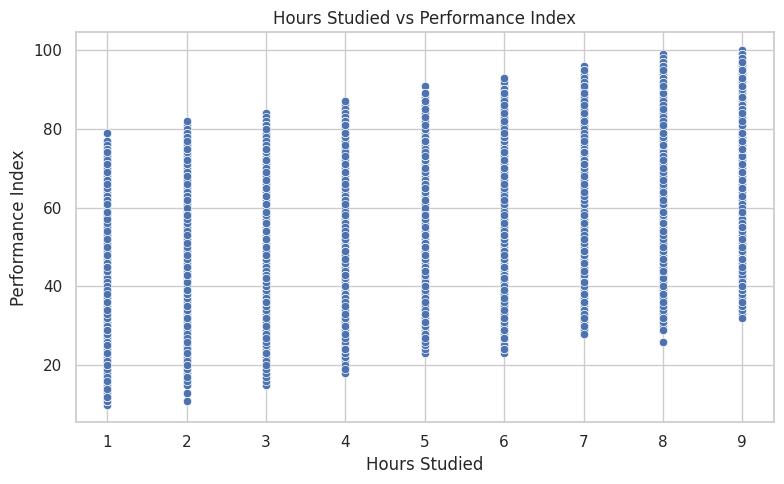

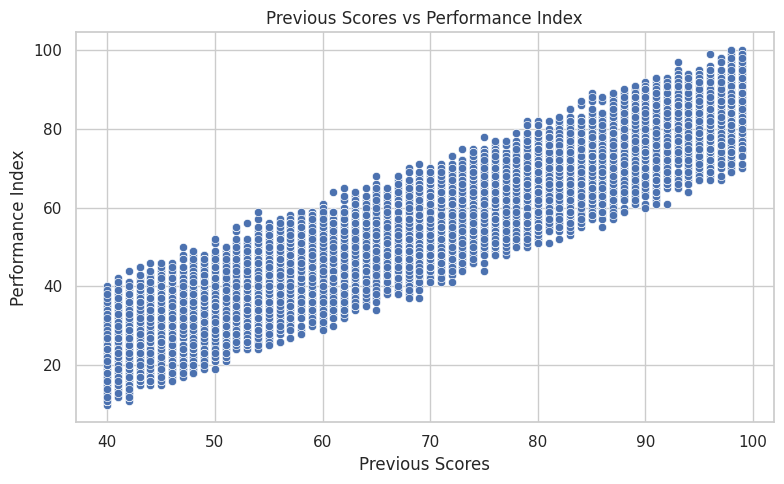

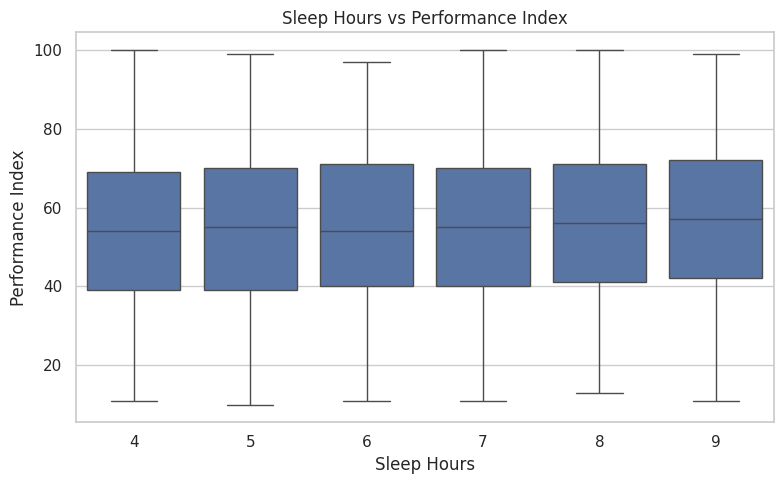

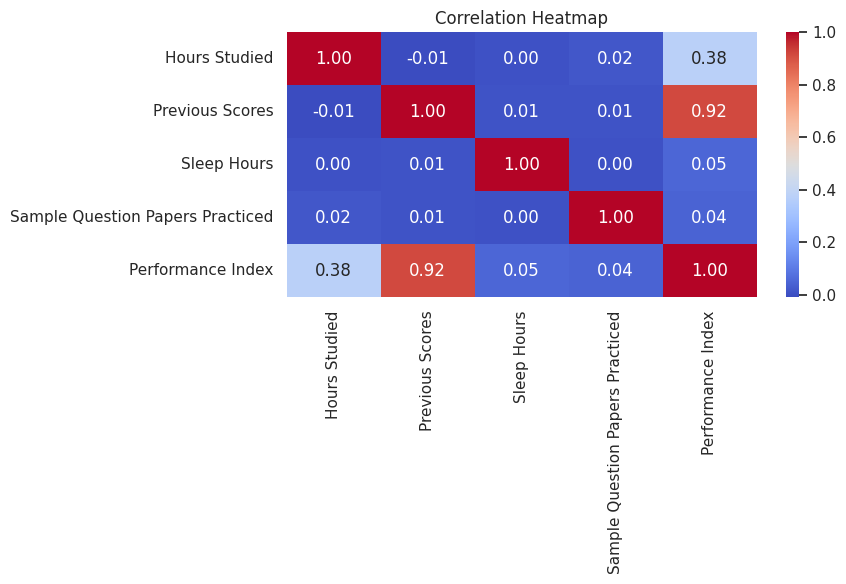


Input Features:
['Hours Studied', 'Previous Scores', 'Sleep Hours', 'Sample Question Papers Practiced', 'Extracurricular Activities_Yes']

Feature Shape: (9873, 5)
Target Shape: (9873,)

Training Samples: 7898
Testing Samples: 1975

Linear Regression Model Trained Successfully!

First 10 Actual Values:
[47. 76. 62. 23. 76. 83. 60. 51. 38. 58.]

First 10 Predicted Values:
[46.48 80.29 61.07 22.71 74.84 84.19 61.99 50.34 38.9  55.75]

========== MODEL EVALUATION ==========
Mean Absolute Error (MAE): 1.647
Mean Squared Error (MSE): 4.306
Root Mean Squared Error (RMSE): 2.075
R2 Score: 0.9884
R2 Score Percentage: 98.84 %


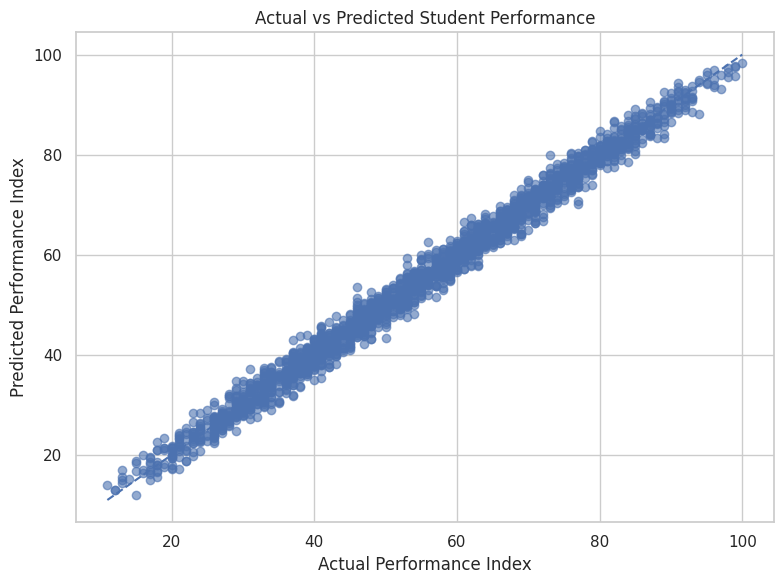

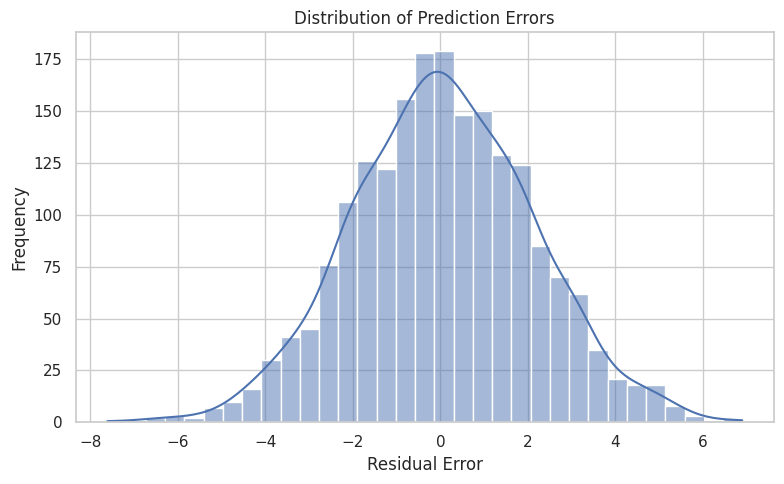

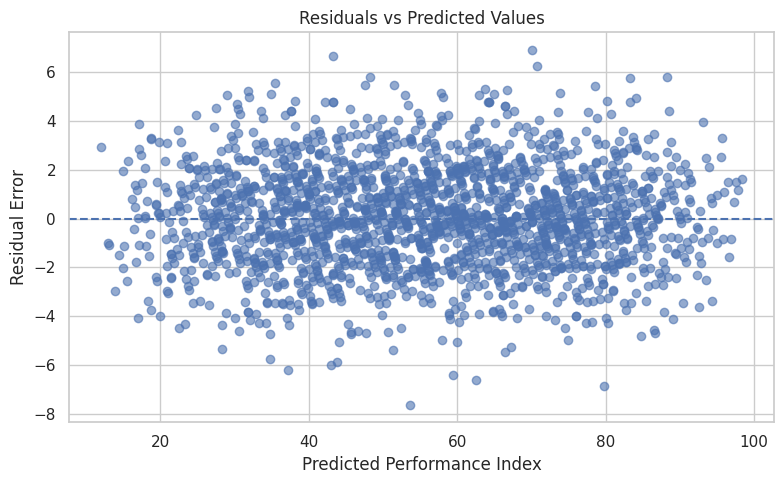


Feature Coefficients:


,Feature,Coefficient
0,Hours Studied,2.851022
1,Previous Scores,1.018430
4,Extracurricular Activities_Yes,0.573823
2,Sleep Hours,0.472073
3,Sample Question Papers Practiced,0.188704


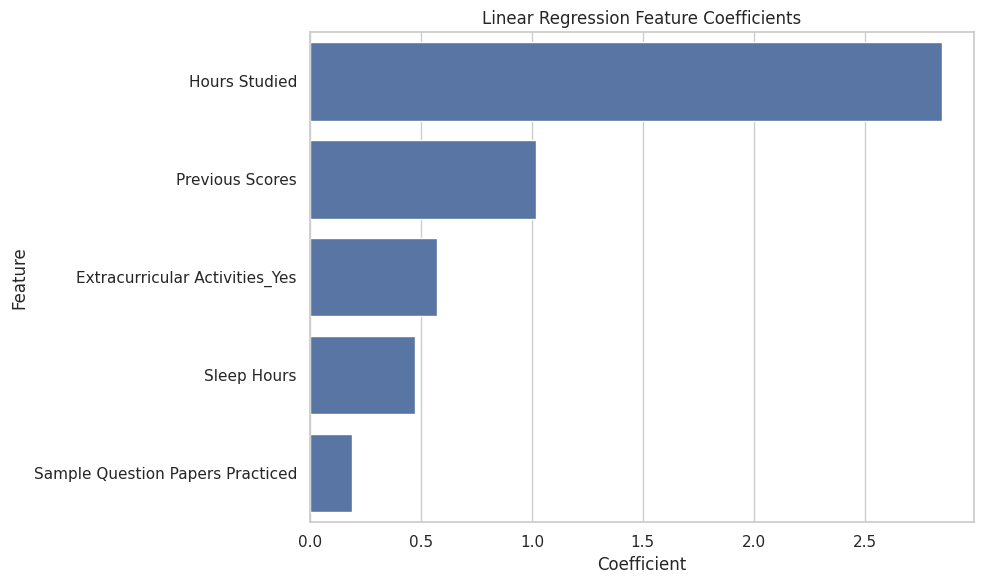


========== STUDENT PERFORMANCE PREDICTION ==========
Hours Studied: 7
Previous Scores: 85
Extracurricular Activities: Yes
Sleep Hours: 8
Sample Question Papers Practiced: 5
Predicted Performance Index: 77.26

Prediction results saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


========== PROJECT SUMMARY ==========
Project: Student Performance Prediction
Algorithm: Linear Regression
Dataset Rows After Cleaning: 9873
Number of Input Features: 5
Training Samples: 7898
Testing Samples: 1975
MAE: 1.647
RMSE: 2.075
R2 Score: 0.9884

Project Completed Successfully!


In [1]:
# ============================================================
# LINEAR REGRESSION PROJECT
# Student Performance Prediction
# ============================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


# 2. UPLOAD DATASET

uploaded = files.upload()

csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)

print("\nDataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


# 3. DATASET INFORMATION

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())


# 4. CHECK MISSING VALUES

print("\nMissing Values:")
print(df.isnull().sum())

df.dropna(inplace=True)


# 5. REMOVE DUPLICATE ROWS

print("\nDuplicate Rows Before Cleaning:")
print(df.duplicated().sum())

df.drop_duplicates(inplace=True)

print("\nDuplicate Rows After Cleaning:")
print(df.duplicated().sum())

print("\nCleaned Dataset Shape:", df.shape)


# 6. DISPLAY COLUMN NAMES

print("\nDataset Columns:")
print(df.columns.tolist())


# 7. PERFORMANCE INDEX DISTRIBUTION

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Performance Index",
    kde=True
)

plt.title("Distribution of Student Performance Index")
plt.xlabel("Performance Index")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


# 8. HOURS STUDIED VS PERFORMANCE

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Hours Studied",
    y="Performance Index"
)

plt.title("Hours Studied vs Performance Index")
plt.tight_layout()
plt.show()


# 9. PREVIOUS SCORES VS PERFORMANCE

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Previous Scores",
    y="Performance Index"
)

plt.title("Previous Scores vs Performance Index")
plt.tight_layout()
plt.show()


# 10. SLEEP HOURS VS PERFORMANCE

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Sleep Hours",
    y="Performance Index"
)

plt.title("Sleep Hours vs Performance Index")
plt.tight_layout()
plt.show()


# 11. CORRELATION HEATMAP

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(9, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


# 12. PREPARE INPUT AND TARGET DATA

y = df["Performance Index"]

X = df.drop(columns=["Performance Index"])

# Convert categorical columns into numeric columns
X = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)

print("\nInput Features:")
print(X.columns.tolist())

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)


# 13. SPLIT DATASET

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])


# 14. TRAIN LINEAR REGRESSION MODEL

model = LinearRegression()

model.fit(X_train, y_train)

print("\nLinear Regression Model Trained Successfully!")


# 15. MAKE PREDICTIONS

y_pred = model.predict(X_test)

print("\nFirst 10 Actual Values:")
print(y_test.head(10).to_numpy())

print("\nFirst 10 Predicted Values:")
print(np.round(y_pred[:10], 2))


# 16. MODEL EVALUATION

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("\n========== MODEL EVALUATION ==========")

print("Mean Absolute Error (MAE):", round(mae, 3))
print("Mean Squared Error (MSE):", round(mse, 3))
print("Root Mean Squared Error (RMSE):", round(rmse, 3))
print("R2 Score:", round(r2, 4))
print("R2 Score Percentage:", round(r2 * 100, 2), "%")


# 17. ACTUAL VS PREDICTED VALUES

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Performance Index")
plt.ylabel("Predicted Performance Index")
plt.title("Actual vs Predicted Student Performance")

plt.tight_layout()
plt.show()


# 18. RESIDUAL DISTRIBUTION

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Residual Error")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


# 19. RESIDUALS VS PREDICTED VALUES

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.6)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Performance Index")
plt.ylabel("Residual Error")
plt.title("Residuals vs Predicted Values")

plt.tight_layout()
plt.show()


# 20. FEATURE COEFFICIENTS

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients["Absolute Coefficient"] = (
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

print("\nFeature Coefficients:")

display(
    coefficients.drop(
        columns="Absolute Coefficient"
    )
)


# 21. FEATURE COEFFICIENT VISUALIZATION

plt.figure(figsize=(10, 6))

sns.barplot(
    data=coefficients,
    x="Coefficient",
    y="Feature"
)

plt.title("Linear Regression Feature Coefficients")
plt.tight_layout()
plt.show()


# 22. PREDICT PERFORMANCE FOR A NEW STUDENT

new_student = pd.DataFrame({
    "Hours Studied": [7],
    "Previous Scores": [85],
    "Extracurricular Activities": ["Yes"],
    "Sleep Hours": [8],
    "Sample Question Papers Practiced": [5]
})

# Encode categorical values
new_student = pd.get_dummies(
    new_student,
    drop_first=True,
    dtype=int
)

# Match the training feature columns
new_student = new_student.reindex(
    columns=X.columns,
    fill_value=0
)

predicted_performance = model.predict(new_student)

print("\n========== STUDENT PERFORMANCE PREDICTION ==========")

print("Hours Studied: 7")
print("Previous Scores: 85")
print("Extracurricular Activities: Yes")
print("Sleep Hours: 8")
print("Sample Question Papers Practiced: 5")

print(
    "Predicted Performance Index:",
    round(predicted_performance[0], 2)
)


# 23. SAVE PREDICTIONS TO CSV

results = pd.DataFrame({
    "Actual Performance Index": y_test.to_numpy(),
    "Predicted Performance Index": y_pred
})

results.to_csv(
    "linear_regression_predictions.csv",
    index=False
)

print("\nPrediction results saved successfully!")


# 24. DOWNLOAD PREDICTIONS

files.download("linear_regression_predictions.csv")


# 25. FINAL PROJECT SUMMARY

print("\n========== PROJECT SUMMARY ==========")

print("Project: Student Performance Prediction")
print("Algorithm: Linear Regression")
print("Dataset Rows After Cleaning:", len(df))
print("Number of Input Features:", X.shape[1])
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 4))

print("\nProject Completed Successfully!")